# 03 · Modeling

A walkthrough of `train.py` step by step. The script is the source of truth; this notebook calls its functions and explains each decision.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image
import train as T

T.FIG_DIR.mkdir(parents=True, exist_ok=True)

## Feature engineering (`src/features.py`)

| Feature | Definition | Why |
|---|---|---|
| `tenure_group` | `pd.cut` into 0–12 / 12–24 / 24–48 / 48+ months | EDA shows churn risk is non-linear in tenure |
| `num_services` | count of service columns equal to "Yes" | more services means a stickier customer |
| `avg_monthly_spend` | `TotalCharges / (tenure + 1)` | the **+1** avoids dividing by zero for new customers |

All features are row-wise, so creating them before the split can't leak test information.

## Train/test split

`stratify=y` keeps the ~73/27 class ratio identical in train and test, so the test score isn't skewed by an unlucky split.

In [2]:
X_train, X_test, y_train, y_test = T.load_data()
print(X_train.shape, X_test.shape)
print(f"Churn rate (train / test): {y_train.mean():.3f} / {y_test.mean():.3f}")

(5634, 22) (1409, 22)
Churn rate (train / test): 0.265 / 0.265


## Pipeline: preventing data leakage

`ColumnTransformer` (StandardScaler on numeric columns, OneHotEncoder on categorical ones) and the model are wrapped in one `Pipeline`. During cross-validation the scaler and encoder are **re-fit on each training fold only**, so no statistics from validation or test data leak into training.

In [3]:
T.build_pipeline(T.MODELS['GradientBoosting'])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## Model comparison (5-fold stratified CV, ROC-AUC)

**ROC-AUC** is the probability that the model ranks a random churner above a random non-churner, and it doesn't depend on the threshold. `class_weight='balanced'` scales up the penalty for mistakes on the minority (churn) class.

In [4]:
comparison = T.compare_models(X_train, y_train)
comparison

LogisticRegression   ROC-AUC 0.8480 ± 0.0115


RandomForest         ROC-AUC 0.8249 ± 0.0115


GradientBoosting     ROC-AUC 0.8467 ± 0.0114


,model,cv_roc_auc_mean,cv_roc_auc_std
0,LogisticRegression,0.848007,0.011493
2,GradientBoosting,0.846721,0.011394
1,RandomForest,0.824883,0.011495


## Hyperparameter tuning (`GridSearchCV`)

Small grids for every candidate. Parameter names use the pipeline step prefix, e.g. `model__max_depth`.

In [5]:
searches = {name: T.tune(name, X_train, y_train) for name in T.MODELS}
comparison['tuned_cv_roc_auc'] = comparison['model'].map({n: s.best_score_ for n, s in searches.items()})
best_name = max(searches, key=lambda n: searches[n].best_score_)
pipe = searches[best_name].best_estimator_
print('Selected:', best_name)
comparison.round(4)

Best LogisticRegression params: {'model__C': 10}  CV ROC-AUC 0.8481


Best RandomForest params: {'model__max_depth': 6, 'model__min_samples_split': 10, 'model__n_estimators': 200}  CV ROC-AUC 0.8475


Best GradientBoosting params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}  CV ROC-AUC 0.8500
Selected: GradientBoosting


,model,cv_roc_auc_mean,cv_roc_auc_std,tuned_cv_roc_auc
0,LogisticRegression,0.8480,0.0115,0.8481
2,GradientBoosting,0.8467,0.0114,0.8500
1,RandomForest,0.8249,0.0115,0.8475


## Threshold tuning: cost-based

Assume losing a customer costs **5×** a retention offer, so cost = `5·FN + 1·FP`. The threshold is chosen on **out-of-fold training predictions**, which leaves the test set untouched. Theory puts the optimum near FP/(FP+FN) = 1/6 ≈ 0.17.

Chosen threshold: 0.15


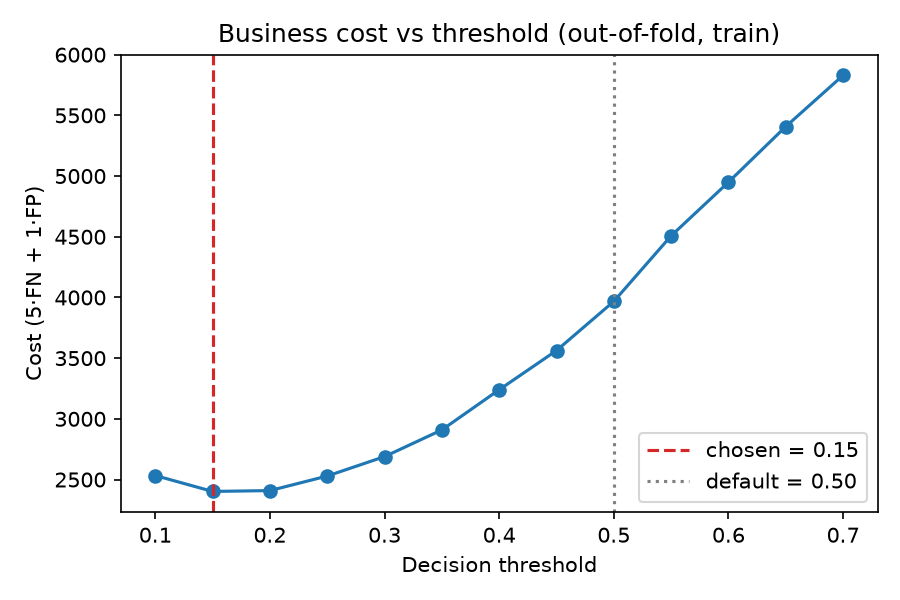

In [6]:
threshold, costs = T.pick_threshold(pipe, X_train, y_train)
print(f'Chosen threshold: {threshold:.2f}')
Image(T.FIG_DIR / 'threshold_cost.png', width=520)

## Test-set evaluation

In [7]:
results = T.evaluate(pipe, X_test, y_test, threshold)
print(f"Test ROC-AUC: {results['test_roc_auc']:.4f}")


Threshold 0.50
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Threshold 0.15
              precision    recall  f1-score   support

           0       0.94      0.60      0.73      1035
           1       0.44      0.89      0.59       374

    accuracy                           0.68      1409
   macro avg       0.69      0.74      0.66      1409
weighted avg       0.81      0.68      0.69      1409

Test ROC-AUC: 0.8461


In [8]:
pd.DataFrame({k: results[k] for k in ['default_0.50', 'tuned']}).drop('confusion_matrix').round(3)

,default_0.50,tuned
threshold,0.5,0.15
churn_precision,0.669039,0.444444
churn_recall,0.502674,0.887701
churn_f1,0.574046,0.592328
accuracy,0.801987,0.675656
business_cost,1023,625


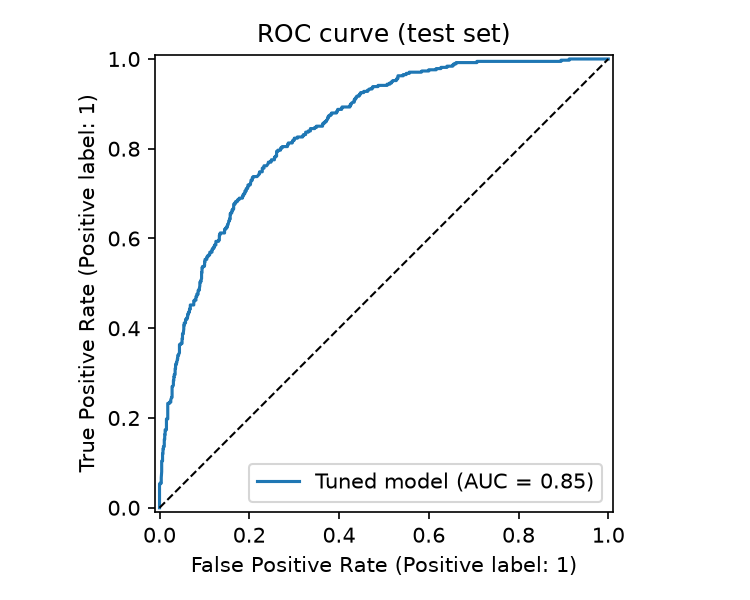

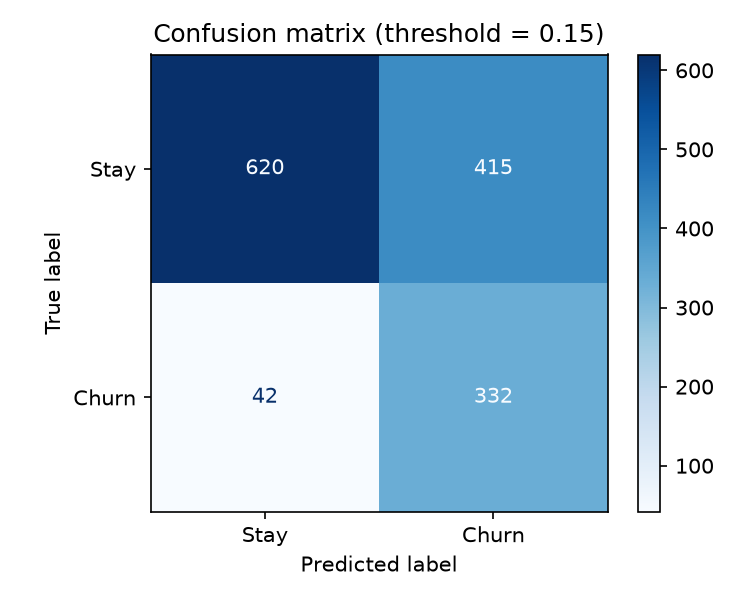

In [9]:
display(Image(T.FIG_DIR / 'roc_curve.png', width=420), Image(T.FIG_DIR / 'confusion_matrix.png', width=420))

Moving from 0.50 to the cost-optimal threshold raises **churner recall from ~50% to ~89%** and cuts total business cost by **~39%**, in exchange for more retention offers going to customers who would have stayed. Those offers are cheap, so the trade is worth it.

## Explainability: SHAP

,mean |SHAP| (one-hot columns grouped)
Contract,0.588
tenure,0.456
InternetService,0.265
OnlineSecurity,0.205
TechSupport,0.190
PaymentMethod,0.166
MonthlyCharges,0.157
PaperlessBilling,0.124
MultipleLines,0.107
OnlineBackup,0.084


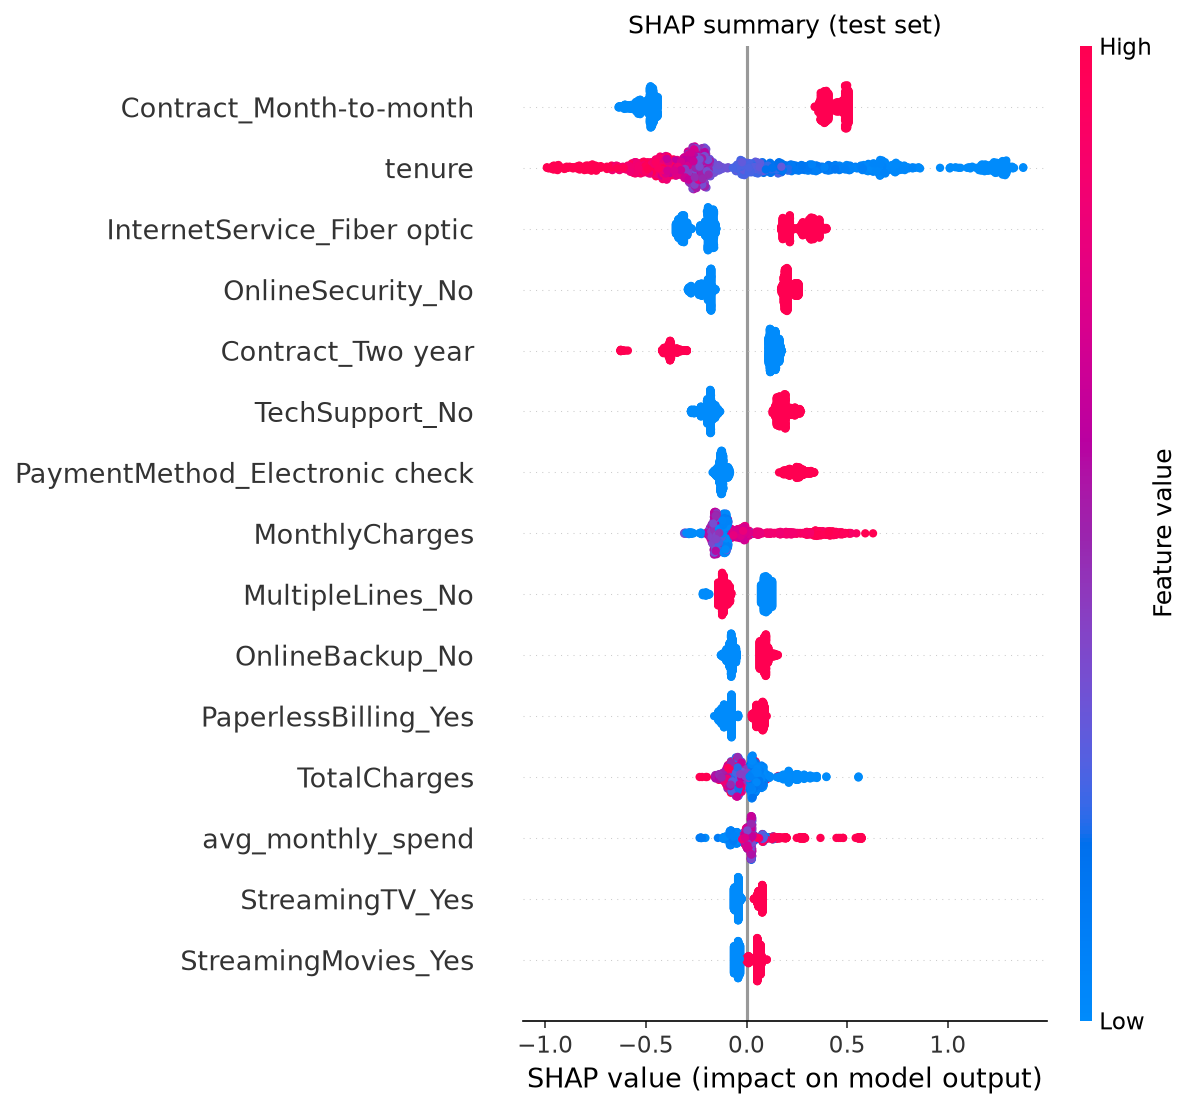

In [10]:
drivers = T.explain(pipe, X_train, X_test)
display(drivers.round(3).to_frame('mean |SHAP| (one-hot columns grouped)'))
Image(T.FIG_DIR / 'shap_summary.png', width=650)

**Top churn drivers:** contract type (month-to-month raises risk), tenure (new customers are at risk) and internet service (fiber optic raises risk), followed by missing OnlineSecurity/TechSupport and electronic-check payment. These match the EDA findings.